# Training Control Panel

Configurable local-or-remote training control panel. Run setup, inventory, configuration, and monitoring in order. Launch and interrupt actions require an exact confirmation value. Set `CUT_CELL_*` environment values to select the data, runtime, remote host, and artifact location.

In [1]:
from __future__ import annotations



import json

import os

import re

import subprocess

import sys

from dataclasses import replace

from datetime import datetime, timezone

from pathlib import Path



import matplotlib.pyplot as plt

import pandas as pd

from IPython.display import display



ROOT = Path.cwd().resolve()

while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():

    ROOT = ROOT.parent

if not (ROOT / "clean_simulation").is_dir():

    raise RuntimeError("Open this notebook from the repository root or a descendant directory.")

if str(ROOT) not in sys.path:

    sys.path.insert(0, str(ROOT))



from clean_simulation.scripts.operations.training_control import (

    EPOCH_PATTERN,

    RemoteTrainingSettings,

)



DEFAULT_REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"

DEFAULT_SSH_KEY = Path.home() / ".ssh" / "ibm_learning.pem"

DEFAULT_REMOTE_PYTHON = "./.venv/bin/python"

DEFAULT_REMOTE_TORCHRUN = "./.venv/bin/torchrun"

SETTINGS = RemoteTrainingSettings.from_environment()

if not SETTINGS.host:

    SETTINGS = replace(SETTINGS, host=DEFAULT_REMOTE_HOST)

if not os.environ.get("CUT_CELL_SSH_KEY"):

    SETTINGS = replace(SETTINGS, ssh_key=DEFAULT_SSH_KEY)

if not os.environ.get("CUT_CELL_REMOTE_PYTHON"):

    SETTINGS = replace(SETTINGS, python=DEFAULT_REMOTE_PYTHON)

if not os.environ.get("CUT_CELL_REMOTE_TORCHRUN"):

    SETTINGS = replace(SETTINGS, torchrun=DEFAULT_REMOTE_TORCHRUN)

REMOTE_HOST = SETTINGS.host

SSH_KEY = SETTINGS.ssh_key

REMOTE_REPO = SETTINGS.repository

REMOTE_RUN_ROOT = SETTINGS.run_root

REMOTE_PYTHON = SETTINGS.python

REMOTE_TORCHRUN = SETTINGS.torchrun

TRAINING_ENTRYPOINT = SETTINGS.training_entrypoint

EXACT_DATA_PATH = SETTINGS.data_path

LOCAL_CACHE_ROOT = ROOT / REMOTE_RUN_ROOT

LOCAL_CACHE_ROOT.mkdir(parents=True, exist_ok=True)



# Compatibility aliases keep the remaining control cells unchanged.

remote_shell = SETTINGS.run_shell

remote_file = SETTINGS.remote_file



host_source = "CUT_CELL_REMOTE_HOST" if os.environ.get("CUT_CELL_REMOTE_HOST") else "DEFAULT_REMOTE_HOST"

key_source = "CUT_CELL_SSH_KEY" if os.environ.get("CUT_CELL_SSH_KEY") else "DEFAULT_SSH_KEY"

print(f"Remote host: {REMOTE_HOST} ({host_source})")

print(f"SSH key: {SSH_KEY} ({key_source})")

print(f"Remote launcher: {REMOTE_TORCHRUN} / {REMOTE_PYTHON}; entry point: {TRAINING_ENTRYPOINT}")

print("For local training, run python -m clean_simulation.scripts.training.train_model with the same CUT_CELL_* settings.")


Remote host: ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com (DEFAULT_REMOTE_HOST)
SSH key: C:\Users\z0058p1u\.ssh\ibm_learning.pem (DEFAULT_SSH_KEY)
Remote launcher: ./.venv/bin/torchrun / ./.venv/bin/python; entry point: -m clean_simulation.scripts.training.train_model
For local training, run python -m clean_simulation.scripts.training.train_model with the same CUT_CELL_* settings.


In [21]:
# Refresh this catalog before selecting a checkpoint or taking an interrupt action.
from clean_simulation.scripts.operations.training_control import build_inventory_script

completed = remote_shell(build_inventory_script(SETTINGS), timeout=90)
catalog_text, remote_status = completed.stdout.split("\nACTIVE\n", maxsplit=1)
run_catalog = pd.DataFrame(json.loads(catalog_text))
CHECKPOINT_CATALOG = run_catalog.dropna(subset=["checkpoint"]).sort_values(["history best", "run"], na_position="last").reset_index(drop=True)
display(run_catalog.sort_values(["history best", "run"], na_position="last").style.format({"checkpoint MiB": "{:.2f}", "history best": "{:.4%}"}, na_rep="--"))
print("ACTIVE" + remote_status)

,run,checkpoint,checkpoint MiB,history epochs,history best,pid
48,w256_l8_adamw_lr1e6_constant_exclude_eggcarton_continuation,clean_simulation/outputs/adaptive_training/w256_l8_adamw_lr1e6_constant_exclude_eggcarton_continuation/stage_01_best.pt,25.00,962,0.1456%,566289
51,w256_l8_adamw_lr3e6_exclude_eggcarton_family_probe,clean_simulation/outputs/adaptive_training/w256_l8_adamw_lr3e6_exclude_eggcarton_family_probe/stage_01_best.pt,24.86,94,0.1458%,563878
29,exact_lattice_transformer_w256_l8_lbfgs_from_best_epoch845_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_lbfgs_from_best_epoch845_gpu1/stage_01_best.pt,24.85,80,0.2460%,417239
30,exact_lattice_transformer_w256_l8_lbfgs_with_persistent_normalizers,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_lbfgs_with_persistent_normalizers/stage_01_best.pt,24.85,80,0.2460%,--
32,exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1/stage_01_best.pt,24.99,845,0.2533%,380630
26,exact_lattice_transformer_w256_l8_from_best_lr2e6_500e_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_from_best_lr2e6_500e_gpu1/stage_01_best.pt,24.87,220,0.2550%,389209
7,best_model_w256_l8_ddp_compile_lr1e6_from_lbfgs,clean_simulation/outputs/adaptive_training/best_model_w256_l8_ddp_compile_lr1e6_from_lbfgs/stage_01_best.pt,24.88,240,0.2576%,524562
53,w256_l8_ddp_persisted_norm_differentiable_lr3e7,clean_simulation/outputs/adaptive_training/w256_l8_ddp_persisted_norm_differentiable_lr3e7/stage_01_best.pt,24.84,17,0.2579%,533255
50,w256_l8_adamw_lr3e6_drop_train_hardest1pct_probe,clean_simulation/outputs/adaptive_training/w256_l8_adamw_lr3e6_drop_train_hardest1pct_probe/stage_01_best.pt,24.84,21,0.2579%,561485
52,w256_l8_ddp_differentiable_norm_lr3e7_probe,clean_simulation/outputs/adaptive_training/w256_l8_ddp_differentiable_norm_lr3e7_probe/stage_01_best.pt,24.84,14,0.2580%,530536


ACTIVE
GPU
0, 0 %, 0 MiB, 97887 MiB
1, 0 %, 0 MiB, 97887 MiB



In [23]:
# Smoke profiles use the best model's width-256, eight-layer ordered-SDF transformer.
# They start from scratch because 8-node checkpoint token and positional tensors are incompatible with richer grids.
if "CHECKPOINT_CATALOG" in globals():
    display(CHECKPOINT_CATALOG[["run", "checkpoint", "history best", "history epochs"]])

RICH_SDF_SMOKE_RUNS = (
    {
        "run_name": "transformer_w256_l8_sdf_8subcells_smoke",
        "checkpoint_run": None,
        "data_path": "clean_simulation/outputs/data/refined_material_parity_8subcells_i2_p1.h5",
        "refined_subcells": 2,
        "model_type": "transformer",
        "fusion_dim": 256,
        "residual_blocks": 8,
        "ordered_sdf_branch": True,
        "epochs": 20,
        "wall_hours": 0.5,
        "batch_size": 4096,
        "initial_lr": 3.0e-5,
        "scheduler_type": "cosine",
        "eta_min_factor": 0.1,
        "compile_mode": "none",
        "distributed": False,
        "cuda_devices": "0",
        "optimizer": "adamw",
        "weight_decay": 1.0e-5,
        "use_amp": True,
        "preserve_estimated_input_normalizers": False,
        "hard_example_drop_fraction": 0.0,
        "excluded_geometry_prefixes": ("eggcarton_sphere",),
        "spike_threshold": 0.05,
        "spike_lr_reduction_factor": 0.5,
        "max_spike_retries": 3,
        "seed": 227344,
    },
    {
        "run_name": "transformer_w256_l8_sdf_27subcells_smoke",
        "checkpoint_run": None,
        "data_path": "clean_simulation/outputs/data/refined_material_parity_27subcells_i2_p1.h5",
        "refined_subcells": 3,
        "model_type": "transformer",
        "fusion_dim": 256,
        "residual_blocks": 8,
        "ordered_sdf_branch": True,
        "epochs": 20,
        "wall_hours": 0.5,
        "batch_size": 4096,
        "initial_lr": 3.0e-5,
        "scheduler_type": "cosine",
        "eta_min_factor": 0.1,
        "compile_mode": "none",
        "distributed": False,
        "cuda_devices": "1",
        "optimizer": "adamw",
        "weight_decay": 1.0e-5,
        "use_amp": True,
        "preserve_estimated_input_normalizers": False,
        "hard_example_drop_fraction": 0.0,
        "excluded_geometry_prefixes": ("eggcarton_sphere",),
        "spike_threshold": 0.05,
        "spike_lr_reduction_factor": 0.5,
        "max_spike_retries": 3,
        "seed": 227345,
    },
)

TRAINING = RICH_SDF_SMOKE_RUNS[0]
display(pd.DataFrame(RICH_SDF_SMOKE_RUNS)[[
    "run_name", "cuda_devices", "refined_subcells", "data_path", "batch_size", "initial_lr", "epochs", "wall_hours",
]])
print("Smoke criterion: stable finite loss and a clear validation decrease over 20 epochs before launching the 72-hour profiles.")

,run,checkpoint,history best,history epochs
0,w256_l8_adamw_lr1e6_constant_exclude_eggcarton...,clean_simulation/outputs/adaptive_training/w25...,0.001456,962
1,w256_l8_adamw_lr3e6_exclude_eggcarton_family_p...,clean_simulation/outputs/adaptive_training/w25...,0.001458,94
2,exact_lattice_transformer_w256_l8_lbfgs_from_b...,clean_simulation/outputs/adaptive_training/exa...,0.002460,80
3,exact_lattice_transformer_w256_l8_lbfgs_with_p...,clean_simulation/outputs/adaptive_training/exa...,0.002460,80
4,exact_lattice_transformer_w256_l8_ordered_sdf_...,clean_simulation/outputs/adaptive_training/exa...,0.002533,845
5,exact_lattice_transformer_w256_l8_from_best_lr...,clean_simulation/outputs/adaptive_training/exa...,0.002550,220
6,best_model_w256_l8_ddp_compile_lr1e6_from_lbfgs,clean_simulation/outputs/adaptive_training/bes...,0.002576,240
7,w256_l8_ddp_persisted_norm_differentiable_lr3e7,clean_simulation/outputs/adaptive_training/w25...,0.002579,17
8,w256_l8_adamw_lr3e6_drop_train_hardest1pct_probe,clean_simulation/outputs/adaptive_training/w25...,0.002579,21
9,w256_l8_ddp_differentiable_norm_lr3e7_probe,clean_simulation/outputs/adaptive_training/w25...,0.002580,14


,run_name,cuda_devices,refined_subcells,data_path,batch_size,initial_lr,epochs,wall_hours
0,transformer_w256_l8_sdf_8subcells_smoke,0,2,clean_simulation/outputs/data/refined_material...,4096,0.00003,20,0.5
1,transformer_w256_l8_sdf_27subcells_smoke,1,3,clean_simulation/outputs/data/refined_material...,4096,0.00003,20,0.5


Smoke criterion: stable finite loss and a clear validation decrease over 20 epochs before launching the 72-hour profiles.


In [24]:
# Regenerate only rich SDF features at the exact prior-corpus rows; stiffness targets are copied unchanged.

# The generator first recomputes and verifies the previous 8-node SDF per geometry, then fails closed on any mismatch.

from clean_simulation.scripts.operations.training_control import build_refined_data_generation_script



RICH_SDF_SOURCE_H5 = os.environ.get(

    "CUT_CELL_RICH_SDF_SOURCE_H5",

    "clean_simulation/outputs/data/exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5",

)

RICH_SDF_DATA_PATHS = {

    2: "clean_simulation/outputs/data/refined_material_parity_8subcells_i2_p1.h5",

    3: "clean_simulation/outputs/data/refined_material_parity_27subcells_i2_p1.h5",

}

RICH_SDF_SMOKE_RUNS = tuple(

    {**profile, "data_path": RICH_SDF_DATA_PATHS[int(profile["refined_subcells"])]}

    for profile in RICH_SDF_SMOKE_RUNS

)

TRAINING = RICH_SDF_SMOKE_RUNS[0]

REMOTE_QUESO_PYTHON_PATH = os.environ.get("CUT_CELL_REMOTE_QUESO_PYTHON_PATH", "QuESo/out/install/linux")

DATA_GENERATION_CONFIRMATION = ""  # Set to GENERATE_RICH_SDF_DATA to start generation.



if DATA_GENERATION_CONFIRMATION == "GENERATE_RICH_SDF_DATA":

    for refined_subcells, data_path in RICH_SDF_DATA_PATHS.items():

        generation_script = build_refined_data_generation_script(

            SETTINGS,

            source_h5=RICH_SDF_SOURCE_H5,

            output_path=data_path,

            refined_subcells=refined_subcells,

            queso_python_path=REMOTE_QUESO_PYTHON_PATH,

        )

        print(remote_shell(generation_script, timeout=7200).stdout.strip())

else:

    display(pd.DataFrame([

        {

            "subcells per FEM cell": subcells ** 3,

            "SDF inputs": (subcells + 1) ** 3,

            "source K corpus": RICH_SDF_SOURCE_H5,

            "output": data_path,

        }

        for subcells, data_path in RICH_SDF_DATA_PATHS.items()

    ]))

    print("Generation is guarded. It copies prior K targets unchanged and recomputes only SDF inputs after verifying the prior 8-node features.")


,subcells per FEM cell,SDF inputs,source K corpus,output
0,8,27,clean_simulation/outputs/data/exact_original_s...,clean_simulation/outputs/data/refined_material...
1,27,64,clean_simulation/outputs/data/exact_original_s...,clean_simulation/outputs/data/refined_material...


Generation is guarded. It copies prior K targets unchanged and recomputes only SDF inputs after verifying the prior 8-node features.


In [ ]:
# Prepared next stage: full-precision L-BFGS local refinement.
# Do not launch this until an AdamW run has produced a demonstrably better checkpoint.
# Copy this profile into TRAINING, set checkpoint_run to that run, give it a unique run_name,
# then use the guarded launch cell below.
LBFGS_REFINEMENT = {
    "run_name": "replace_with_unique_lbfgs_refinement_name",
    "checkpoint_run": "exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1",
    "model_type": "transformer",
    "fusion_dim": 256,
    "residual_blocks": 8,
    "ordered_sdf_branch": True,
    "epochs": 80,
    "wall_hours": 5,
    "batch_size": 2048,
    "initial_lr": 0.2,
    "eta_min_factor": 1.0,
    "optimizer": "lbfgs",
    "weight_decay": 0.0,
    "use_amp": False,
    "lbfgs_max_iter": 4,
    "lbfgs_history_size": 20,
    "seed": 227344,
}
display(pd.DataFrame([LBFGS_REFINEMENT]))
print("Readiness rule: use only a checkpoint whose best validation is below the current medium baseline; L-BFGS is a basin refinement, not an escape mechanism.")

In [ ]:
# Guarded launch. batch_size is per process when distributed=True.
LAUNCH_CONFIRMATION = "transformer_w256_l8_sdf_8subcells_smoke"  # Set this to the exact run_name to confirm launch.

if LAUNCH_CONFIRMATION != TRAINING["run_name"]:
    raise RuntimeError("Launch blocked. Set LAUNCH_CONFIRMATION to the exact configured run_name.")
if TRAINING["run_name"] in set(run_catalog["run"]):
    raise RuntimeError("Launch blocked. Use a new run_name; existing run directories are never overwritten.")

optimizer = TRAINING.get("optimizer", "adamw").lower()
use_amp = bool(TRAINING.get("use_amp", True))
weight_decay = float(TRAINING.get("weight_decay", 1.0e-5))
hard_example_drop_fraction = float(TRAINING.get("hard_example_drop_fraction", 0.0))
compile_mode = TRAINING.get("compile_mode", "none").lower()
scheduler_type = TRAINING.get("scheduler_type", "cosine").lower()
refined_subcells = int(TRAINING.get("refined_subcells", 1))
checkpoint_run = TRAINING.get("checkpoint_run")
if optimizer not in {"adamw", "sgd", "lbfgs"}:
    raise RuntimeError("optimizer must be adamw, sgd, or lbfgs.")
if not 0.0 <= hard_example_drop_fraction < 1.0:
    raise RuntimeError("hard_example_drop_fraction must be in [0, 1).")
if optimizer == "lbfgs" and (use_amp or weight_decay != 0.0):
    raise RuntimeError("L-BFGS requires use_amp=False and weight_decay=0.0.")
if compile_mode not in {"none", "default", "reduce-overhead", "max-autotune"}:
    raise RuntimeError("compile_mode must be none, default, reduce-overhead, or max-autotune.")
if scheduler_type not in {"none", "cosine"}:
    raise RuntimeError("scheduler_type must be none or cosine.")
if refined_subcells < 1:
    raise RuntimeError("refined_subcells must be at least one.")
if checkpoint_run is not None and checkpoint_run not in set(CHECKPOINT_CATALOG["run"]):
    raise RuntimeError("Launch blocked. checkpoint_run is not in the current catalog.")

from clean_simulation.scripts.operations.training_control import build_launch_script

checkpoint = None if checkpoint_run is None else CHECKPOINT_CATALOG.set_index("run").loc[checkpoint_run, "checkpoint"]
launch_script = build_launch_script(SETTINGS, TRAINING, checkpoint=checkpoint)
print(remote_shell(launch_script, timeout=90).stdout.strip())

Launched two-rank DDP training in clean_simulation/outputs/adaptive_training/w256_l8_adamw_lr3e6_drop_train_hardest1pct_probe with PID 561485 on physical GPU(s) 0,1.


In [ ]:
# Guarded interruption. Refresh the inventory, set both values to the exact run name, then run.
RUN_TO_INTERRUPT = "w256_l8_ddp_persisted_norm_differentiable_lr3e7"
INTERRUPT_CONFIRMATION = "w256_l8_ddp_persisted_norm_differentiable_lr3e7"

if RUN_TO_INTERRUPT != INTERRUPT_CONFIRMATION or not RUN_TO_INTERRUPT:
    raise RuntimeError("Interrupt blocked. Set RUN_TO_INTERRUPT and INTERRUPT_CONFIRMATION to the same exact run name.")

from clean_simulation.scripts.operations.training_control import build_interrupt_script

interrupt_script = build_interrupt_script(SETTINGS, RUN_TO_INTERRUPT)
print(remote_shell(interrupt_script).stdout.strip())

RuntimeError: remote_shell timed out after 30s — SSH session likely stuck (see diagnosis above).

,run,completed epoch,latest validation,best validation,latest LR
0,transformer_w256_l8_sdf_27subcells_noegg_topologyx10_b4096_lr8e7_v11,1156,0.2225%,0.2224%,5.67e-07
1,transformer_w256_l8_sdf_8subcells_noegg_topologyx10_b4096_lr4e7_v11,2464,0.2368%,0.2364%,2.77e-07


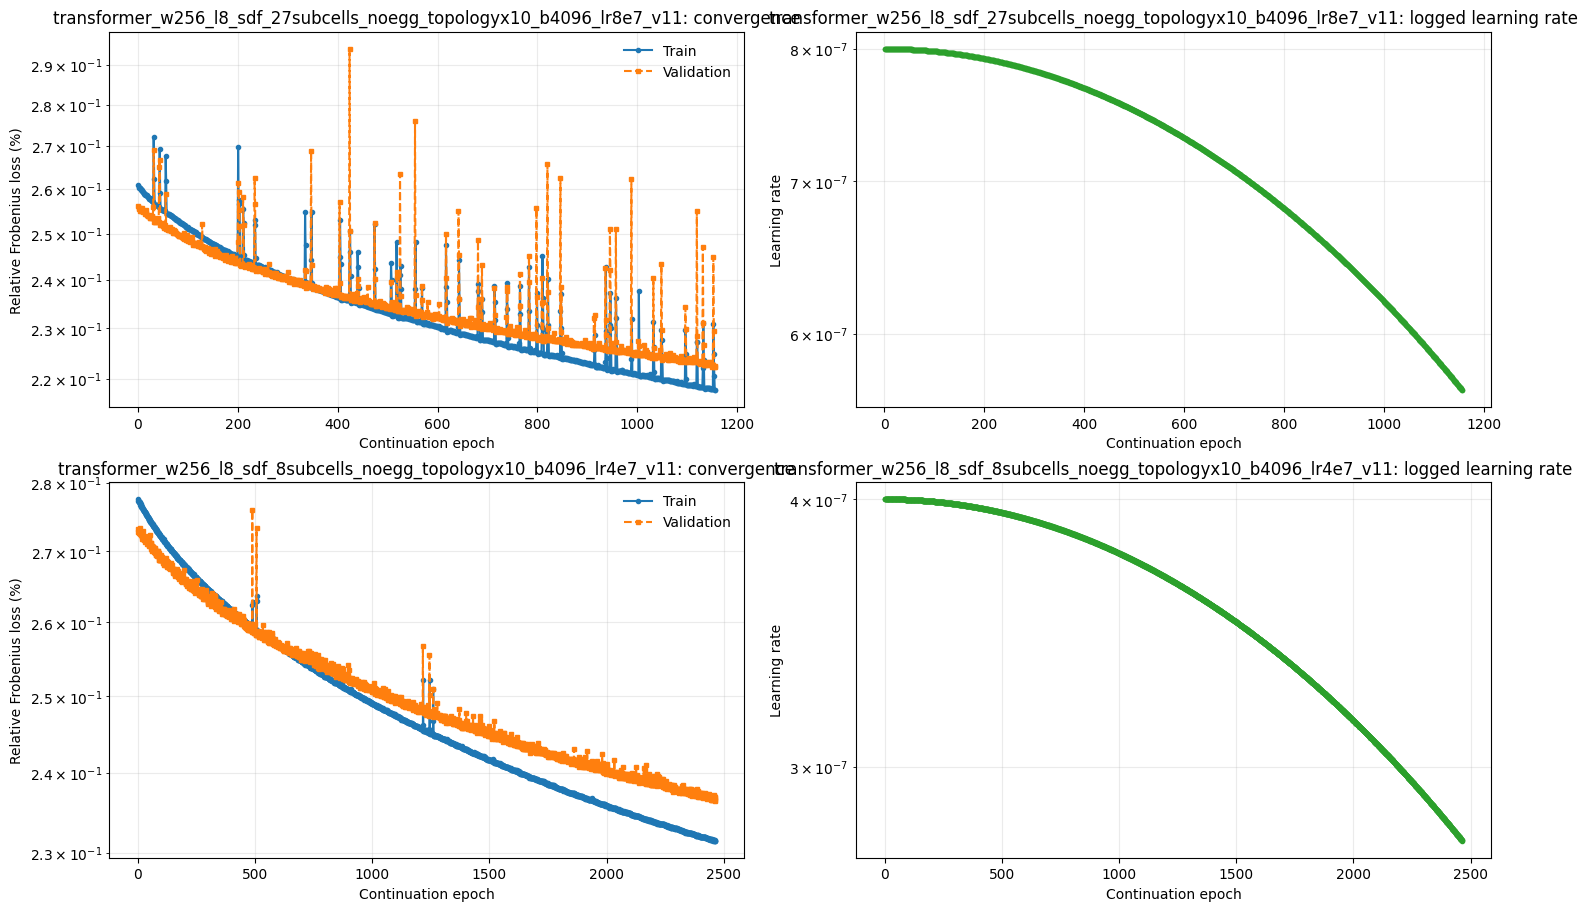

Synchronized 2026-09-11 11:55:27 UTC


In [2]:
# Monitor all live training processes. Each run gets its own loss and learning-rate axes.
from clean_simulation.scripts.operations.training_control import build_active_runs_script, parse_epoch_log, synchronize_training_log

active_runs = json.loads(remote_shell(build_active_runs_script(SETTINGS), timeout=90).stdout)
histories = {}
for record in active_runs:
    run_name = record["run"]
    local_log = LOCAL_CACHE_ROOT / run_name / "training.log"
    copied = synchronize_training_log(SETTINGS, run_name, local_log, atomically=True)
    if copied.returncode:
        print(f"Could not synchronize {run_name}: {copied.stderr.strip()}")
        continue
    rows = parse_epoch_log(local_log.read_text(encoding="utf-8", errors="replace"))
    if rows:
        histories[run_name] = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")

if not histories:
    print("No active run has completed a validation epoch yet.")
else:
    summary_rows = [
        {"run": name, "completed epoch": int(history.epoch.max()), "latest validation": history.val_loss.iloc[-1], "best validation": history.val_loss.min(), "latest LR": history.learning_rate.iloc[-1]}
        for name, history in histories.items()
    ]
    display(pd.DataFrame(summary_rows).style.format({"latest validation": "{:.4%}", "best validation": "{:.4%}", "latest LR": "{:.2e}"}))
    figure, axes = plt.subplots(len(histories), 2, figsize=(15, 4.5 * len(histories)), squeeze=False, constrained_layout=True)
    for row, (run_name, history) in enumerate(histories.items()):
        loss_axis, lr_axis = axes[row]
        loss_axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        loss_axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        loss_axis.set(title=f"{run_name}: convergence", xlabel="Continuation epoch", ylabel="Relative Frobenius loss (%)")
        lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:green")
        lr_axis.set(title=f"{run_name}: logged learning rate", xlabel="Continuation epoch", ylabel="Learning rate")
        for axis in (loss_axis, lr_axis):
            axis.grid(True, which="both", alpha=0.25)
        loss_axis.legend(frameon=False)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

In [19]:
# Track the rich-SDF smoke or 72-hour runs together. Refresh this cell after launching.
from clean_simulation.scripts.operations.training_control import build_run_status_script, synchronize_training_log

RICH_SDF_RUN_NAMES = tuple(profile["run_name"] for profile in RICH_SDF_SMOKE_RUNS)
RICH_SDF_EXPECTED_INPUTS = {
    profile["run_name"]: (int(profile["refined_subcells"]) + 1) ** 3
    for profile in RICH_SDF_SMOKE_RUNS
}
rich_sdf_histories = {}
rich_sdf_status = []
for run_name in RICH_SDF_RUN_NAMES:
    try:
        state_lines = remote_shell(build_run_status_script(SETTINGS, run_name), timeout=90).stdout.strip().splitlines()
        if len(state_lines) != 2:
            raise RuntimeError(f"Remote status returned {len(state_lines)} line(s), expected state and PID.")
        run_state, pid = state_lines
    except RuntimeError as error:
        rich_sdf_status.append({"run": run_name, "state": "not launched", "detail": str(error)})
        continue

    local_log = LOCAL_CACHE_ROOT / run_name / "training.log"
    copied = synchronize_training_log(SETTINGS, run_name, local_log, atomically=True)
    if copied.returncode:
        rich_sdf_status.append({"run": run_name, "state": run_state.lower(), "PID": pid, "detail": copied.stderr.strip()})
        continue

    log_text = local_log.read_text(encoding="utf-8", errors="replace")
    expected_inputs = RICH_SDF_EXPECTED_INPUTS[run_name]
    input_match = re.search(r"inputs=(\d+) signed distances", log_text)
    recorded_inputs = int(input_match.group(1)) if input_match else None
    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr)}
        for epoch, train, validation, lr in EPOCH_PATTERN.findall(log_text)
    ]
    detail = "input width verified" if recorded_inputs == expected_inputs else f"expected {expected_inputs} inputs, logged {recorded_inputs}"
    rich_sdf_status.append({
        "run": run_name,
        "state": run_state.lower(),
        "PID": pid,
        "expected inputs": expected_inputs,
        "logged inputs": recorded_inputs,
        "detail": detail,
    })
    if rows:
        rich_sdf_histories[run_name] = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")

display(pd.DataFrame(rich_sdf_status))
if not rich_sdf_histories:
    print("No rich-SDF run has completed a validation epoch yet.")
else:
    summary_rows = [
        {
            "run": run_name,
            "completed epoch": int(history.epoch.max()),
            "latest validation": history.val_loss.iloc[-1],
            "best validation": history.val_loss.min(),
            "latest LR": history.learning_rate.iloc[-1],
        }
        for run_name, history in rich_sdf_histories.items()
    ]
    display(pd.DataFrame(summary_rows).style.format({
        "latest validation": "{:.4%}", "best validation": "{:.4%}", "latest LR": "{:.2e}",
    }))
    figure, axes = plt.subplots(len(rich_sdf_histories), 2, figsize=(15, 4.5 * len(rich_sdf_histories)), squeeze=False, constrained_layout=True)
    for row, (run_name, history) in enumerate(rich_sdf_histories.items()):
        loss_axis, lr_axis = axes[row]
        loss_axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        loss_axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        loss_axis.set(title=f"{run_name}: convergence", xlabel="Epoch", ylabel="Relative Frobenius loss (%)")
        loss_axis.grid(True, which="both", alpha=0.25)
        loss_axis.legend(frameon=False)
        lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:green")
        lr_axis.set(title=f"{run_name}: learning rate", xlabel="Epoch", ylabel="Learning rate")
        lr_axis.grid(True, which="both", alpha=0.25)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

,run,state,detail
0,transformer_w256_l8_sdf_8subcells_smoke,not launched,"Remote status returned 1 line(s), expected sta..."
1,transformer_w256_l8_sdf_27subcells_smoke,not launched,"Remote status returned 1 line(s), expected sta..."


No rich-SDF run has completed a validation epoch yet.
Synchronized 2026-09-04 12:52:58 UTC


In [ ]:
# Automatically track train and validation loss for every currently running training process.
from clean_simulation.scripts.operations.training_control import build_active_runs_script, synchronize_training_log

live_runs = json.loads(remote_shell(build_active_runs_script(SETTINGS)).stdout)
live_histories = {}
for record in live_runs:
    live_run = record["run"]
    local_log = LOCAL_CACHE_ROOT / live_run / "training.log"
    copied = synchronize_training_log(SETTINGS, live_run, local_log)
    if copied.returncode:
        print(f"Could not synchronize {live_run}: {copied.stderr.strip()}")
        continue
    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation)}
        for epoch, train, validation, _ in EPOCH_PATTERN.findall(local_log.read_text(encoding="utf-8", errors="replace"))
    ]
    if rows:
        live_histories[live_run] = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")

if not live_histories:
    print("No currently running model has completed a validation epoch yet.")
else:
    summary = pd.DataFrame([
        {"run": live_run, "completed epoch": int(history.epoch.max()), "latest train": history.train_loss.iloc[-1], "latest validation": history.val_loss.iloc[-1], "best validation": history.val_loss.min()}
        for live_run, history in live_histories.items()
    ])
    display(summary.style.format({"latest train": "{:.4%}", "latest validation": "{:.4%}", "best validation": "{:.4%}"}))
    figure, axes = plt.subplots(len(live_histories), 1, figsize=(12, 4.5 * len(live_histories)), squeeze=False, constrained_layout=True)
    for axis, (live_run, history) in zip(axes[:, 0], live_histories.items()):
        axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        axis.set(title=f"{live_run}: train and validation loss", xlabel="Continuation epoch", ylabel="Relative Frobenius loss (%)")
        axis.grid(True, which="both", alpha=0.25)
        axis.legend(frameon=False)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

No currently running model has completed a validation epoch yet.
Synchronized 2026-09-02 11:10:08 UTC


,run,state,PID,expected inputs,logged inputs,input width,baseline,baseline source
0,transformer_w256_l8_sdf_8subcells_local_refine_b4096_lr2e6,active,939573,27,27,verified,0.3667%,Preserved best
1,transformer_w256_l8_sdf_27subcells_local_refine_b4096_lr2e6,active,939574,64,64,verified,0.3466%,Preserved best


,run,completed epoch,latest validation,best validation,improvement from baseline (bp),latest LR
0,transformer_w256_l8_sdf_8subcells_local_refine_b4096_lr2e6,1790,0.2894%,0.2894%,+7.73,9.61e-07
1,transformer_w256_l8_sdf_27subcells_local_refine_b4096_lr2e6,840,0.2771%,0.2770%,+6.96,1.71e-06


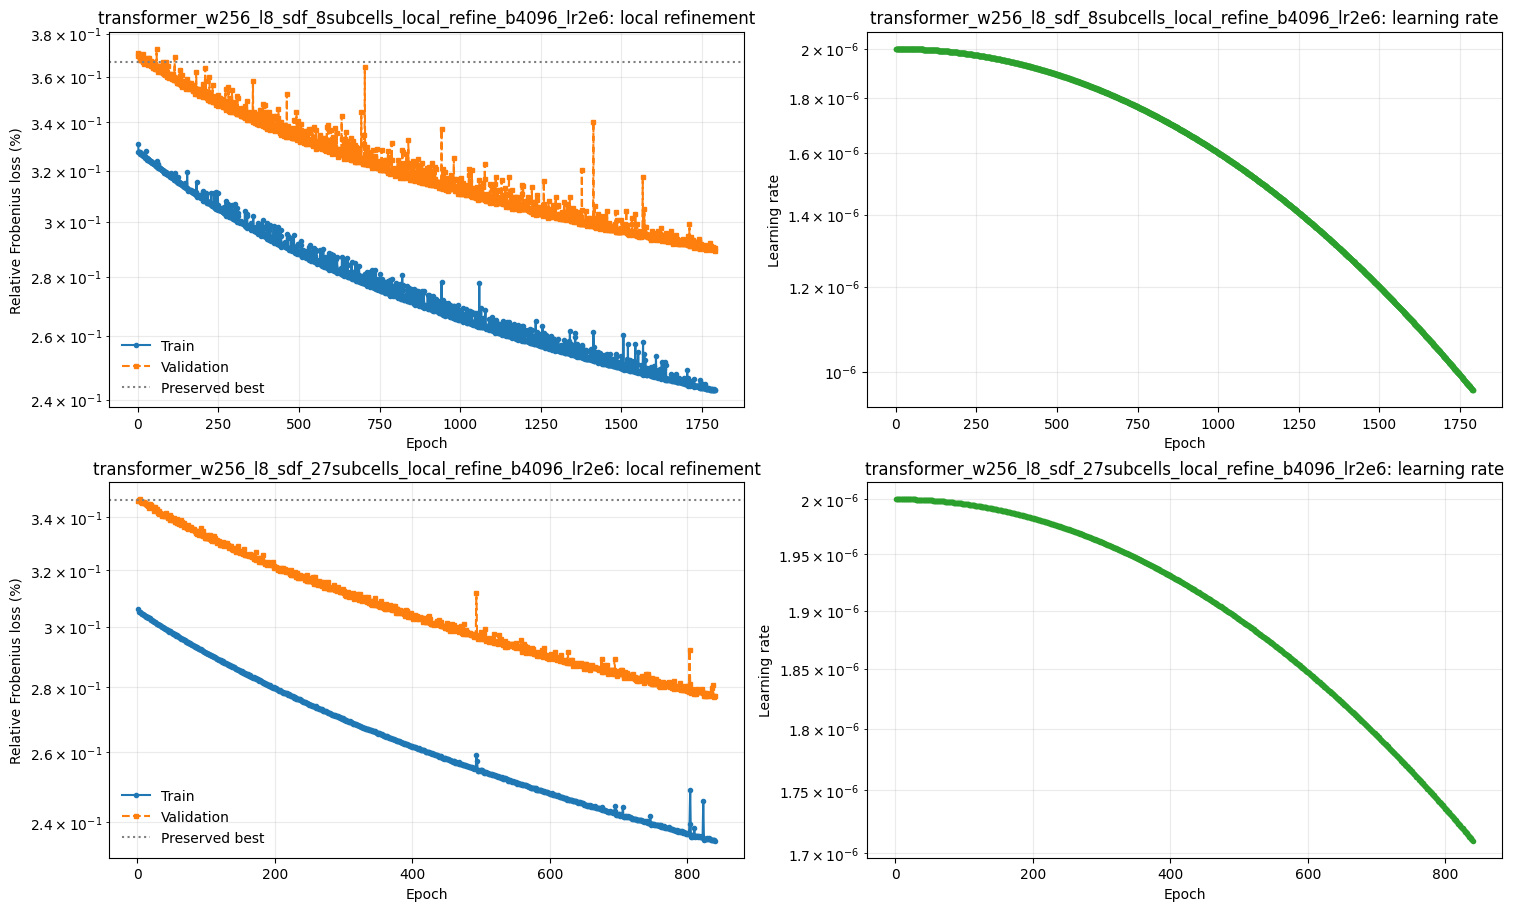

Synchronized 2026-09-08 14:53:43 UTC


In [14]:
# Paired rich-SDF local-refinement tracker. Run after the setup cell.
import base64

RICH_SDF_LONG_RUNS = (
    ("transformer_w256_l8_sdf_8subcells_local_refine_b4096_lr2e6", 27, 0.0036667464373681914, "Preserved best"),
    ("transformer_w256_l8_sdf_27subcells_local_refine_b4096_lr2e6", 64, 0.0034662598105521187, "Preserved best"),
)

ssh_options = [
    "-o", "ConnectTimeout=15",
    "-o", "BatchMode=yes",
    "-o", "UserKnownHostsFile=NUL",
    "-o", "StrictHostKeyChecking=no",
    "-i", str(SSH_KEY),
]
remote_root = "clean_simulation/outputs/adaptive_training"
long_run_status = []
long_run_histories = {}
for run_name, expected_inputs, baseline, baseline_label in RICH_SDF_LONG_RUNS:
    status_script = f"""set -euo pipefail
cd {REMOTE_REPO}
pid=$(cat {remote_root}/{run_name}/pid)
if kill -0 \"$pid\" 2>/dev/null; then echo ACTIVE; else echo FINISHED; fi
echo \"$pid\"
cat {remote_root}/{run_name}/training.log
"""
    encoded = base64.b64encode(status_script.encode("utf-8")).decode("ascii")
    completed = None
    failures = []
    for attempt in range(8):
        candidate = subprocess.run(
            ["ssh", *ssh_options, REMOTE_HOST, f"echo {encoded} | base64 -d | bash"],
            capture_output=True,
            text=True,
            timeout=90,
        )
        if not candidate.returncode:
            completed = candidate
            break
        failures.append(candidate.stderr.strip())
    if completed is None:
        long_run_status.append({"run": run_name, "state": "unavailable", "detail": failures[-1] if failures else "SSH failed"})
        continue

    state, pid, log_text = completed.stdout.split("\n", maxsplit=2)
    input_match = re.search(r"inputs=(\d+) signed distances", log_text)
    logged_inputs = int(input_match.group(1)) if input_match else None
    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr)}
        for epoch, train, validation, lr in EPOCH_PATTERN.findall(log_text)
    ]
    long_run_status.append({
        "run": run_name,
        "state": state.lower(),
        "PID": pid,
        "expected inputs": expected_inputs,
        "logged inputs": logged_inputs,
        "input width": "verified" if logged_inputs == expected_inputs else "mismatch",
        "baseline": baseline,
        "baseline source": baseline_label,
    })
    if rows:
        long_run_histories[run_name] = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")

display(pd.DataFrame(long_run_status).style.format({"baseline": "{:.4%}"}))
if not long_run_histories:
    if any(row["state"] != "unavailable" for row in long_run_status):
        print("The local-refinement runs are reachable, but neither has completed a validation epoch yet.")
    else:
        print("The local-refinement runs could not be reached through the current AWS load-balancer backend.")
else:
    baselines = {run_name: baseline for run_name, _, baseline, _ in RICH_SDF_LONG_RUNS}
    baseline_labels = {run_name: label for run_name, _, _, label in RICH_SDF_LONG_RUNS}
    summary = pd.DataFrame([
        {
            "run": run_name,
            "completed epoch": int(history.epoch.max()),
            "latest validation": history.val_loss.iloc[-1],
            "best validation": history.val_loss.min(),
            "improvement from baseline (bp)": (baselines[run_name] - history.val_loss.min()) * 10000,
            "latest LR": history.learning_rate.iloc[-1],
        }
        for run_name, history in long_run_histories.items()
    ])
    display(summary.style.format({
        "latest validation": "{:.4%}", "best validation": "{:.4%}",
        "improvement from baseline (bp)": "{:+.2f}", "latest LR": "{:.2e}",
    }))
    figure, axes = plt.subplots(len(long_run_histories), 2, figsize=(15, 4.5 * len(long_run_histories)), squeeze=False, constrained_layout=True)
    for row, (run_name, history) in enumerate(long_run_histories.items()):
        loss_axis, lr_axis = axes[row]
        loss_axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        loss_axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        loss_axis.axhline(100 * baselines[run_name], color="tab:gray", linestyle=":", label=baseline_labels[run_name])
        loss_axis.set(title=f"{run_name}: local refinement", xlabel="Epoch", ylabel="Relative Frobenius loss (%)")
        loss_axis.grid(True, which="both", alpha=0.25)
        loss_axis.legend(frameon=False)
        lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:green")
        lr_axis.set(title=f"{run_name}: learning rate", xlabel="Epoch", ylabel="Learning rate")
        lr_axis.grid(True, which="both", alpha=0.25)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

Tracking w256_l8_adamw_lr1e6_constant_exclude_eggcarton_continuation (finished, PID 566289, GPUs 0 and 1).
[13:56:55] Starting transformer: width=256, blocks=8, residual_scaling=rezero, ordered_sdf_branch=True, batch=8192, lr=1.0e-06 -> 1.0e-06, epochs=1000, wall_seconds=10800.0, optimizer=adamw, scheduler=none, amp=True, seed=227344, split_seed=227344, shuffle_seed=227344, spike_threshold=5.0%, spike_factor=0.5, max_spike_retries=3, resume=True, cpu_threads=1, workers=16, prefetch=4, tf32=True, compile_mode=none, preserve_estimated_input_normalizers=False, hard_example_drop_fraction=0.00%, excluded_geometry_prefixes=('eggcarton_sphere',), distributed=True, inputs=8 signed distances only, gpu=NVIDIA RTX PRO 6000 Blackwell Server Edition.
Excluded 471,736 row(s) for geometry prefixes ('eggcarton_sphere',); retained 1,835,944 from exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5 before splitting.


,state,completed epoch,latest validation,best validation,best epoch,change from exclusion-split baseline (bp),latest LR
0,finished,962,0.1457%,0.1456%,792,-0.026,2.50e-07


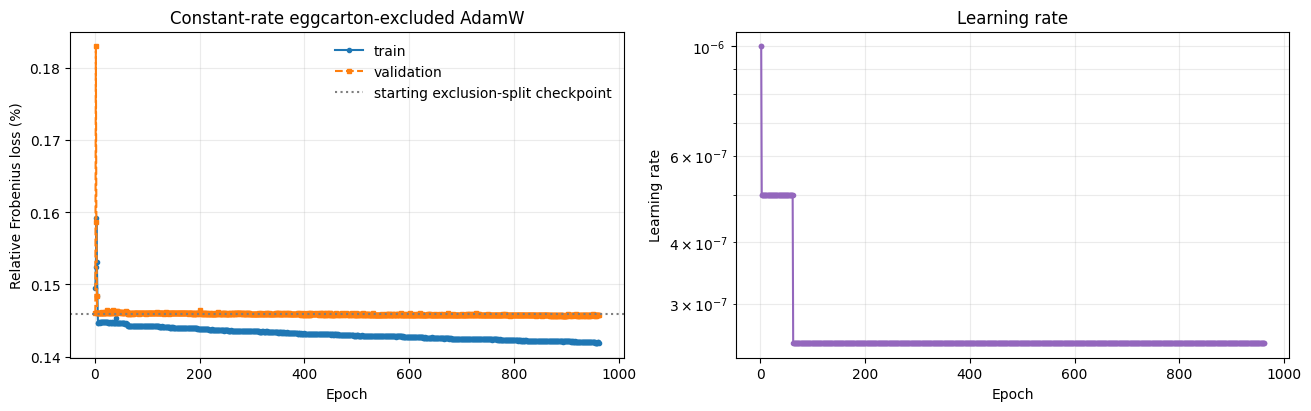

Synchronized 2026-09-04 07:47:19 UTC


In [3]:
# Track one selected run. Set CUT_CELL_TRACKED_RUN before opening the notebook, or use the configured TRAINING run.
from clean_simulation.scripts.operations.training_control import build_run_status_script, synchronize_training_log

TRACKED_RUN = os.environ.get("CUT_CELL_TRACKED_RUN", TRAINING["run_name"] if "TRAINING" in globals() else "")
TRACKED_BASELINE = os.environ.get("CUT_CELL_TRACKED_BASELINE", "")
if not TRACKED_RUN:
    raise RuntimeError("Set CUT_CELL_TRACKED_RUN or run the training configuration cell first.")
baseline = float(TRACKED_BASELINE) if TRACKED_BASELINE else None

run_state, pid = remote_shell(build_run_status_script(SETTINGS, TRACKED_RUN), timeout=90).stdout.strip().splitlines()
print(f"Tracking {TRACKED_RUN} ({run_state.lower()}, PID {pid}).")

tracked_log = LOCAL_CACHE_ROOT / TRACKED_RUN / "training.log"
copied = synchronize_training_log(SETTINGS, TRACKED_RUN, tracked_log)
if copied.returncode:
    raise RuntimeError(copied.stderr.strip() or f"Could not synchronize {TRACKED_RUN}.")
log_text = tracked_log.read_text(encoding="utf-8", errors="replace")
for line in log_text.splitlines():
    if line.startswith("Excluded ") or "Starting transformer" in line:
        print(line)
rows = [
    {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr), "seconds": float(seconds)}
    for epoch, train, validation, lr, seconds in re.findall(
        r"Epoch\s+(\d+)\s*/\s*\d+\s+\| Train: ([0-9.eE+-]+) \| Val: ([0-9.eE+-]+).*?Lr: ([0-9.eE+-]+) \| Time: ([0-9.eE+-]+)s", log_text,
    )
]
history = pd.DataFrame(rows)
if history.empty:
    print("No completed validation epoch yet.")
else:
    history = history.drop_duplicates("epoch", keep="last").sort_values("epoch")
    best = history.loc[history.val_loss.idxmin()]
    summary = {
        "state": run_state.lower(),
        "completed epoch": int(history.epoch.max()),
        "latest validation": history.val_loss.iloc[-1],
        "best validation": best.val_loss,
        "best epoch": int(best.epoch),
        "latest LR": history.learning_rate.iloc[-1],
    }
    if baseline is not None:
        summary["change from baseline (bp)"] = (best.val_loss - baseline) * 10000
    display(pd.DataFrame([summary]).style.format({
        "latest validation": "{:.4%}", "best validation": "{:.4%}",
        "change from baseline (bp)": "{:+.3f}", "latest LR": "{:.2e}",
    }))
    figure, (loss_axis, lr_axis) = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    loss_axis.plot(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="train")
    loss_axis.plot(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="validation")
    if baseline is not None:
        loss_axis.axhline(100 * baseline, color="tab:gray", linestyle=":", label="baseline")
    loss_axis.set(title=f"{TRACKED_RUN}: convergence", xlabel="Epoch", ylabel="Relative Frobenius loss (%)")
    loss_axis.grid(True, alpha=0.25); loss_axis.legend(frameon=False)
    lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:purple")
    lr_axis.set(title="Learning rate", xlabel="Epoch", ylabel="Learning rate")
    lr_axis.grid(True, which="both", alpha=0.25)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

,run,state,PID,expected inputs,logged inputs,baseline validation,epoch,latest validation,best validation,best epoch,improvement from baseline (bp),trailing validation min,trailing validation max,latest LR
0,transformer_w256_l8_sdf_8subcells_noegg_topologyx10_b4096_lr4e7_v11,active,1139963,27,27,0.2746%,2252,0.2382%,0.2381%,2250,+3.65,0.2381%,0.2392%,2.95e-07
1,transformer_w256_l8_sdf_27subcells_noegg_topologyx10_b4096_lr8e7_v11,active,1139964,64,64,0.2560%,1057,0.2248%,0.2237%,1050,+3.23,0.2237%,0.2433%,6.01e-07


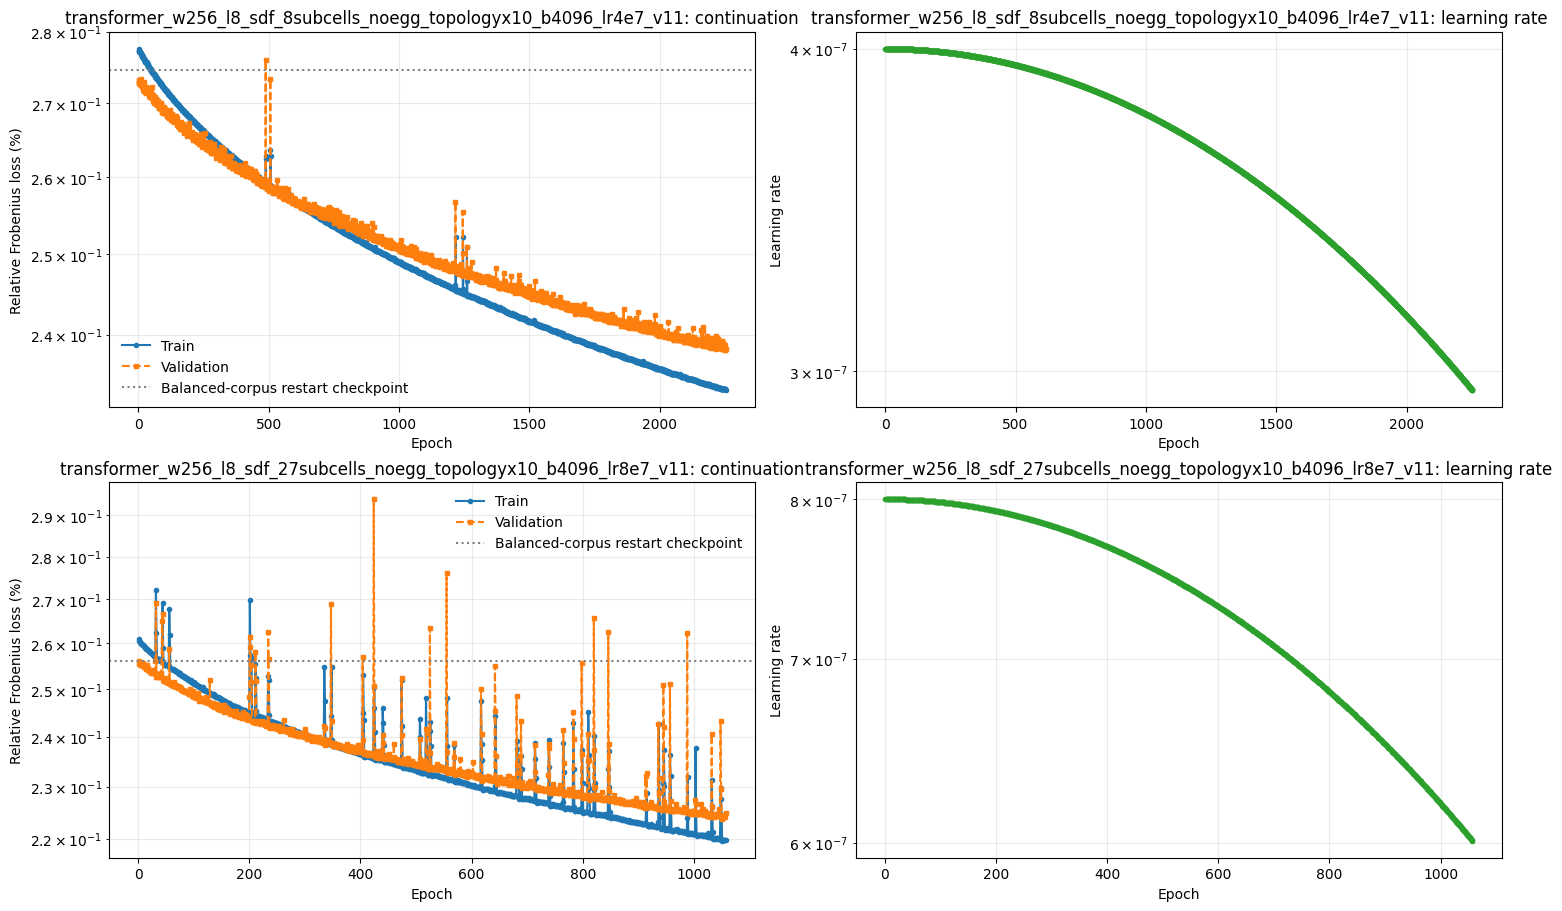

Synchronized 2026-09-11 09:37:50 UTC


In [127]:
# Eggcarton-free topology-balanced rich-SDF continuation tracker.
import base64

TRACKED_RUNS = (
    ("transformer_w256_l8_sdf_8subcells_noegg_topologyx10_b4096_lr4e7_v11", 27, 0.002746178),
    ("transformer_w256_l8_sdf_27subcells_noegg_topologyx10_b4096_lr8e7_v11", 64, 0.002560427),
)

tracker_ssh_options = [
    "-o", "ConnectTimeout=15",
    "-o", "BatchMode=yes",
    "-o", "UserKnownHostsFile=NUL",
    "-o", "StrictHostKeyChecking=no",
    "-i", str(SSH_KEY),
]
tracker_root = "clean_simulation/outputs/adaptive_training"
tracked_histories = {}
tracked_status = []

for run_name, expected_inputs, baseline in TRACKED_RUNS:
    tracker_script = f"""set -euo pipefail
cd {REMOTE_REPO}
pid=$(cat {tracker_root}/{run_name}/pid)
if kill -0 \"$pid\" 2>/dev/null; then echo ACTIVE; else echo FINISHED; fi
echo \"$pid\"
cat {tracker_root}/{run_name}/training.log
"""
    encoded = base64.b64encode(tracker_script.encode("utf-8")).decode("ascii")
    completed = None
    failures = []
    for attempt in range(8):
        candidate = subprocess.run(
            ["ssh", *tracker_ssh_options, REMOTE_HOST, f"echo {encoded} | base64 -d | bash"],
            capture_output=True,
            text=True,
            timeout=90,
        )
        if not candidate.returncode:
            completed = candidate
            break
        failures.append(candidate.stderr.strip())
    if completed is None:
        tracked_status.append({"run": run_name, "state": "unavailable", "detail": failures[-1] if failures else "SSH failed"})
        continue

    state, pid, log_text = completed.stdout.split("\n", maxsplit=2)
    input_match = re.search(r"inputs=(\d+) signed distances", log_text)
    logged_inputs = int(input_match.group(1)) if input_match else None
    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr)}
        for epoch, train, validation, lr in EPOCH_PATTERN.findall(log_text)
    ]
    history = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch") if rows else pd.DataFrame()
    status = {
        "run": run_name,
        "state": state.lower(),
        "PID": pid,
        "expected inputs": expected_inputs,
        "logged inputs": logged_inputs,
        "baseline validation": baseline,
    }
    if history.empty:
        status["detail"] = "No completed validation epoch"
    else:
        best = history.loc[history.val_loss.idxmin()]
        trailing = history.tail(min(20, len(history))).val_loss
        status.update({
            "epoch": int(history.epoch.max()),
            "latest validation": history.val_loss.iloc[-1],
            "best validation": best.val_loss,
            "best epoch": int(best.epoch),
            "improvement from baseline (bp)": (baseline - best.val_loss) * 10000,
            "trailing validation min": trailing.min(),
            "trailing validation max": trailing.max(),
            "latest LR": history.learning_rate.iloc[-1],
        })
        tracked_histories[run_name] = (history, baseline)
    tracked_status.append(status)

status_frame = pd.DataFrame(tracked_status)
display(status_frame.style.format({
    "baseline validation": "{:.4%}", "latest validation": "{:.4%}", "best validation": "{:.4%}",
    "improvement from baseline (bp)": "{:+.2f}", "trailing validation min": "{:.4%}",
    "trailing validation max": "{:.4%}", "latest LR": "{:.2e}",
}, na_rep="--"))

if tracked_histories:
    figure, axes = plt.subplots(len(tracked_histories), 2, figsize=(15, 4.5 * len(tracked_histories)), squeeze=False, constrained_layout=True)
    for row, (run_name, (history, baseline)) in enumerate(tracked_histories.items()):
        loss_axis, lr_axis = axes[row]
        loss_axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        loss_axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        loss_axis.axhline(100 * baseline, color="tab:gray", linestyle=":", label="Balanced-corpus restart checkpoint")
        loss_axis.set(title=f"{run_name}: continuation", xlabel="Epoch", ylabel="Relative Frobenius loss (%)")
        loss_axis.grid(True, which="both", alpha=0.25)
        loss_axis.legend(frameon=False)  
        lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:green")
        lr_axis.set(title=f"{run_name}: learning rate", xlabel="Epoch", ylabel="Learning rate")
        lr_axis.grid(True, which="both", alpha=0.25)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")